# Méthodes statistiques traditionnelles

Notebook d'appui à la rédaction de la section « Méthodes » : principes, avantages et limites de
quatre familles de modèles statistiques utilisées pour la prédiction probabiliste de résultats
sportifs :

1. **Régression logistique** ;
2. **Systèmes de classement de type Elo** (et variantes) ;
3. **Glicko / Glicko-2** (classement avec incertitude) ;
4. **Approches bayésiennes** (conjugaison, régression logistique bayésienne, rétrécissement).

L'objectif est de **décrire** les méthodes. Les illustrations utilisent les vraies données de la
LNH (saison régulière, 2005-2006 à 2025-2026), avec quelques variables simples connues avant le
match (`nhl_forecast.features.jeu_base`), sans recherche de la meilleure configuration : la
comparaison rigoureuse des modèles est faite dans `03_experimentation/`.

Avec `SAUVER = True`, les figures sont enregistrées en PNG (300 dpi) dans
`reports/map6009/figures/` et les tableaux en CSV dans `reports/map6009/tables/`
(préfixe `methodes_`).

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy import stats
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from nhl_forecast.config import PROJECT_ROOT
from nhl_forecast.features.jeu_base import DESCRIPTIONS, charger_jeu_base
from nhl_forecast.visualization.style import COULEURS, ENCRE, ENCRE_2, appliquer_style

In [3]:
SAUVER = True  # True : enregistre aussi les figures (PNG) et tableaux (CSV) pour le rapport
FIG_DIR = PROJECT_ROOT / "reports" / "map6009" / "figures"
TAB_DIR = PROJECT_ROOT / "reports" / "map6009" / "tables"

pd.set_option("display.max_colwidth", 120)
appliquer_style()  # couleurs + traits/marqueurs/hachures : lisible en noir et blanc
rng = np.random.default_rng(6009)


def sauver(fig, nom):
    if SAUVER:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{nom}.png", dpi=300, bbox_inches="tight", facecolor="white")


def sauver_tableau(df, nom):
    if SAUVER:
        TAB_DIR.mkdir(parents=True, exist_ok=True)
        df.to_csv(TAB_DIR / f"{nom}.csv", encoding="utf-8")
    return df


def log_loss(y, p, eps=1e-12):
    y, p = np.asarray(y, float), np.clip(np.asarray(p, float), eps, 1 - eps)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def brier(y, p):
    return float(np.mean((np.asarray(p, float) - np.asarray(y, float)) ** 2))


def libelle(s):
    """2005 -> « 2005-06 »."""
    return f"{s}-{(s + 1) % 100:02d}"

## Données utilisées

Un match par ligne ; cible : victoire de l'équipe locale (prolongation et tirs de barrage
inclus). Les variables sont des **écarts local − visiteur** de statistiques calculées sur les
matchs précédents (voir `01_donnees/cadrage_probleme.ipynb`). Pour les illustrations qui
demandent un entraînement, on utilise les saisons 2008-2009 à 2021-2022 (MoneyPuck disponible
depuis 2008) et on évalue sur 2022-2023 à 2025-2026.

In [4]:
matchs, equipes = charger_jeu_base()
y_all = matchs["victoire_locale"].to_numpy()
ENTR = matchs["saison"].between(2008, 2021)
TEST = matchs["saison"] >= 2022
NOMS = equipes.drop_duplicates("teamId").set_index("teamId")["teamFullName"]
print(
    f"{len(matchs):,} matchs ({libelle(matchs.saison.min())} à {libelle(matchs.saison.max())}) ; "
    f"victoires locales : {y_all.mean():.1%}"
)

25,302 matchs (2005-06 à 2025-26) ; victoires locales : 54.5%


---
## 1. Régression logistique

**Principe.** La régression logistique modélise la log-cote (logit) de la probabilité de
victoire comme une combinaison **linéaire** des variables explicatives $\mathbf{x}$ :

$$\log\frac{p}{1-p} = \beta_0 + \boldsymbol\beta^\top \mathbf{x}
\quad\Longleftrightarrow\quad p = \sigma(\beta_0 + \boldsymbol\beta^\top \mathbf{x}),
\qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Les coefficients sont estimés par maximum de vraisemblance, ce qui revient à minimiser la
**log loss** (entropie croisée) — exactement la règle de score utilisée pour évaluer les
probabilités. En pratique on ajoute une pénalité $\lambda\lVert\boldsymbol\beta\rVert_2^2$
(ridge) ou $\lambda\lVert\boldsymbol\beta\rVert_1$ (lasso) pour limiter le surapprentissage
lorsque les variables sont nombreuses et corrélées.

**Interprétation.** $e^{\beta_j}$ est le rapport de cotes associé à une augmentation d'une
unité de $x_j$. Lorsque les variables sont des écarts local − visiteur, $\beta_0$ représente
l'**avantage du domicile** : à équipes égales ($\mathbf x = 0$), $p = \sigma(\beta_0)$.

Exemple avec une seule variable, l'écart de part des buts attendus (xG%) de la saison à date.
Les points sont les proportions observées de victoires locales par vingtile de l'écart.

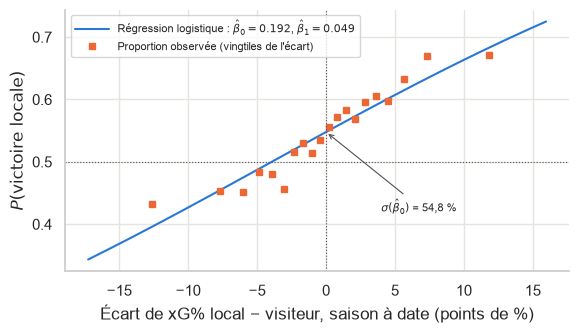

Rapport de cotes pour +1 point d'écart de xG% : 1.050 (16,109 matchs, 2008-09 à 2021-22)


In [5]:
d = matchs.loc[ENTR, ["d_xg_pct_saison", "victoire_locale"]].dropna()
x1 = 100 * d["d_xg_pct_saison"].to_numpy()  # points de pourcentage
lr1 = LogisticRegression(C=1e6).fit(x1.reshape(-1, 1), d["victoire_locale"])
b0, b1 = lr1.intercept_[0], lr1.coef_[0, 0]

q = pd.qcut(x1, 20, labels=False)
emp = pd.DataFrame({"x": x1, "y": d["victoire_locale"].to_numpy(), "q": q}).groupby("q").mean()
xg = np.linspace(*np.quantile(x1, [0.005, 0.995]), 300)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(
    xg,
    expit(b0 + b1 * xg),
    color=COULEURS[0],
    ls="-",
    marker="",
    label=f"Régression logistique : $\\hat\\beta_0 = {b0:.3f}$, $\\hat\\beta_1 = {b1:.3f}$",
)
ax.plot(
    emp["x"],
    emp["y"],
    color=COULEURS[1],
    ls="",
    marker="s",
    ms=5,
    label="Proportion observée (vingtiles de l'écart)",
)
ax.axhline(0.5, color=ENCRE_2, lw=0.8, ls=":")
ax.axvline(0, color=ENCRE_2, lw=0.8, ls=":")
ax.annotate(
    f"$\\sigma(\\hat\\beta_0)$ = {expit(b0):.1%}".replace(".", ",").replace("%", " %"),
    xy=(0, expit(b0)),
    xytext=(4, 0.42),
    fontsize=8,
    arrowprops=dict(arrowstyle="->", color=ENCRE_2, lw=0.8),
)
ax.set_xlabel("Écart de xG% local − visiteur, saison à date (points de %)")
ax.set_ylabel("$P(\\text{victoire locale})$")
ax.legend(loc="upper left", fontsize=8)
sauver(fig, "methodes_logistique_sigmoide")
plt.show()
print(
    f"Rapport de cotes pour +1 point d'écart de xG% : {np.exp(b1):.3f} "
    f"({len(d):,} matchs, {libelle(2008)} à {libelle(2021)})"
)

Sur l'étendue réaliste des écarts, la sigmoïde est presque **linéaire** et les probabilités
restent entre environ 35 % et 70 % : le hockey comporte une grande part d'aléatoire.

Avec deux variables, les courbes d'isoprobabilité sont des **droites parallèles** : le modèle
ne peut représenter ni interaction ni effet non linéaire, sauf si on les crée explicitement
(termes croisés, transformations, splines). Exemple : écart de xG% (saison) et écart de % des
points sur les 10 derniers matchs (forme récente) ; 600 matchs de test tirés au hasard.

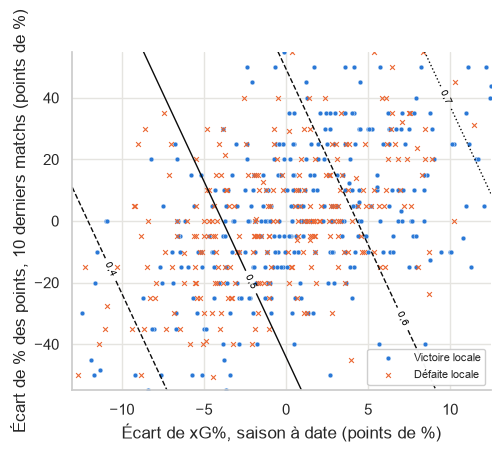

In [6]:
V2 = ["d_xg_pct_saison", "d_pts_pct_10"]
d2 = matchs.loc[ENTR, [*V2, "victoire_locale"]].dropna()
lr2 = LogisticRegression().fit(100 * d2[V2].to_numpy(), d2["victoire_locale"])
t2 = matchs.loc[TEST, [*V2, "victoire_locale"]].dropna().sample(600, random_state=1)
X2, y2 = 100 * t2[V2].to_numpy(), t2["victoire_locale"].to_numpy()

lim = np.quantile(100 * d2[V2].to_numpy(), [0.01, 0.99], axis=0)
xx, yy = np.meshgrid(np.linspace(lim[0, 0], lim[1, 0], 200), np.linspace(lim[0, 1], lim[1, 1], 200))
P = lr2.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(5.4, 4.4))
cs = ax.contour(
    xx,
    yy,
    P,
    levels=[0.3, 0.4, 0.5, 0.6, 0.7],
    colors=ENCRE,
    linewidths=1,
    linestyles=[":", "--", "-", "--", ":"],
)
ax.clabel(cs, fmt=lambda v: f"{v:.1f}".replace(".", ","), fontsize=7)
ax.scatter(
    *X2[y2 == 1].T,
    s=12,
    marker="o",
    facecolor=COULEURS[0],
    edgecolor="white",
    lw=0.3,
    label="Victoire locale",
)
ax.scatter(*X2[y2 == 0].T, s=12, marker="x", color=COULEURS[1], lw=0.8, label="Défaite locale")
ax.set(
    xlabel="Écart de xG%, saison à date (points de %)",
    ylabel="Écart de % des points, 10 derniers matchs (points de %)",
    xlim=lim[:, 0],
    ylim=lim[:, 1],
)
ax.legend(loc="lower right", fontsize=8, framealpha=0.95)
sauver(fig, "methodes_logistique_frontiere")
plt.show()

Les deux classes se chevauchent presque entièrement : avec des données sportives, l'enjeu
n'est pas de **séparer** les victoires des défaites, mais d'estimer correctement leur
**probabilité**.

**Régularisation.** Les statistiques de hockey sont fortement corrélées (% des points,
différentiel de buts, xG%, Corsi%…). Le chemin de régularisation montre l'évolution des
coefficients (variables standardisées) lorsque la pénalité diminue ($C = 1/\lambda$ augmente).
Le ridge ($L_2$) rétrécit tous les coefficients vers zéro et répartit l'effet entre variables
corrélées ; le lasso ($L_1$) en annule certains et effectue une **sélection de variables**.
Les deux panneaux se lisent en parallèle (même axe vertical).

Corrélations entre variables :
                     d_pts_pct_saison  d_diff_buts_saison  d_xg_pct_saison  d_corsi_pct_saison  d_pts_pct_10  d_partant_sv_saison
d_pts_pct_saison                 1.00                0.91             0.53                0.31          0.71                 0.38
d_diff_buts_saison               0.91                1.00             0.58                0.36          0.65                 0.41
d_xg_pct_saison                  0.53                0.58             1.00                0.75          0.38                 0.08
d_corsi_pct_saison               0.31                0.36             0.75                1.00          0.21                -0.05
d_pts_pct_10                     0.71                0.65             0.38                0.21          1.00                 0.30
d_partant_sv_saison              0.38                0.41             0.08               -0.05          0.30                 1.00


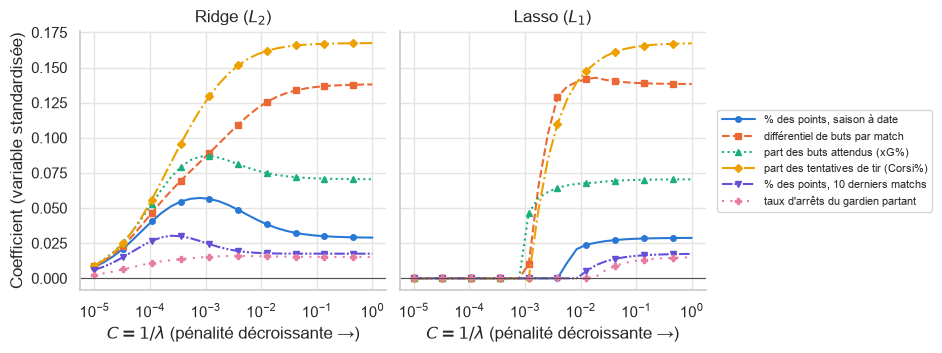

In [7]:
V6 = [
    "d_pts_pct_saison",
    "d_diff_buts_saison",
    "d_xg_pct_saison",
    "d_corsi_pct_saison",
    "d_pts_pct_10",
    "d_partant_sv_saison",
]
d6 = matchs.loc[ENTR, [*V6, "victoire_locale"]].dropna()
X6 = StandardScaler().fit_transform(d6[V6])
y6 = d6["victoire_locale"].to_numpy()
print("Corrélations entre variables :")
print(d6[V6].corr().round(2).to_string())

Cs = np.logspace(-5, 0, 30)
chemins = {}
for nom, l1 in [("Ridge ($L_2$)", 0.0), ("Lasso ($L_1$)", 1.0)]:
    chemins[nom] = np.array(
        [
            LogisticRegression(C=c, l1_ratio=l1, solver="saga", max_iter=5000).fit(X6, y6).coef_[0]
            for c in Cs
        ]
    )

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
for ax, (nom, coefs) in zip(axes, chemins.items(), strict=True):
    for j, v in enumerate(V6):
        ax.plot(Cs, coefs[:, j], markevery=3, label=DESCRIPTIONS[v])
    ax.axhline(0, color=ENCRE_2, lw=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("$C = 1/\\lambda$ (pénalité décroissante →)")
    ax.set_title(nom)
axes[0].set_ylabel("Coefficient (variable standardisée)")
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8)
fig.tight_layout()
sauver(fig, "methodes_logistique_regularisation")
plt.show()

**Interprétation des coefficients.** Régression logistique à plusieurs variables (standardisées,
pénalité ridge faible) : le rapport de cotes indique l'effet multiplicatif sur la cote de
victoire locale d'une augmentation d'un écart-type de la variable, **à autres variables
constantes**. Avec des variables corrélées, ces effets partiels sont plus petits (voire de signe
inversé) que les effets marginaux, ce qui rend l'interprétation délicate.

In [8]:
V8 = [
    "d_pts_pct_saison",
    "d_diff_buts_saison",
    "d_xg_pct_saison",
    "d_corsi_pct_saison",
    "d_pts_pct_10",
    "d_pp_pct_saison",
    "d_repos",
    "d_partant_sv_saison",
]
d8 = matchs.loc[ENTR, [*V8, "victoire_locale"]].dropna()
sc8 = StandardScaler().fit(d8[V8])
lr8 = LogisticRegression(C=1.0).fit(sc8.transform(d8[V8]), d8["victoire_locale"])
coefs = pd.DataFrame(
    {
        "Variable (écart local − visiteur)": [DESCRIPTIONS[v] for v in V8],
        "Écart-type": sc8.scale_,
        "Coefficient": lr8.coef_[0],
        "Rapport de cotes (+1 é.-t.)": np.exp(lr8.coef_[0]),
    }
).set_index("Variable (écart local − visiteur)")
coefs.loc["Constante (avantage du domicile)"] = [
    np.nan,
    lr8.intercept_[0],
    np.exp(lr8.intercept_[0]),
]
P_TR = d8.victoire_locale.mean()
t8 = matchs.loc[TEST, [*V8, "victoire_locale"]].dropna()
p8 = lr8.predict_proba(sc8.transform(t8[V8]))[:, 1]
print(f"P(victoire locale) à équipes égales : {expit(lr8.intercept_[0]):.1%}")
print(
    f"Test ({len(t8):,} matchs) : log loss = {log_loss(t8.victoire_locale, p8):.4f} ; "
    f"probabilité constante = {log_loss(t8.victoire_locale, np.full(len(t8), P_TR)):.4f}"
)
sauver_tableau(coefs.round(4), "methodes_tab_logistique_coefficients")
coefs.round(3)

P(victoire locale) à équipes égales : 54.6%
Test (4,664 matchs) : log loss = 0.6675 ; probabilité constante = 0.6906


,Écart-type,Coefficient,Rapport de cotes (+1 é.-t.)
Variable (écart local − visiteur),,,
"% des points, saison à date",0.164,0.030,1.030
différentiel de buts par match,0.879,0.111,1.117
part des buts attendus (xG%),0.050,0.061,1.063
part des tentatives de tir (Corsi%),0.041,0.179,1.196
"% des points, 10 derniers matchs",0.237,0.018,1.018
efficacité en avantage numérique,0.073,0.059,1.060
jours de repos (max. 5),1.100,0.049,1.050
taux d'arrêts du gardien partant,0.023,0.023,1.023
Constante (avantage du domicile),NaN,0.185,1.203


**Avantages.** Simple, rapide, peu de données requises ; coefficients interprétables ;
minimise directement la log loss, donc probabilités généralement **bien calibrées** lorsque le
modèle est bien spécifié ; référence (*baseline*) incontournable dans la littérature.

**Limites.** Relation linéaire sur l'échelle logit : interactions et non-linéarités doivent être
construites à la main ; sensible à la multicolinéarité (forte entre tirs, Corsi, xG, points)
sans régularisation ; ne modélise pas la dynamique temporelle (la forme récente doit être
encodée dans les variables).

---
## 2. Systèmes de classement Elo

**Principe.** Chaque équipe possède une cote $R$ mise à jour après chaque match. La
probabilité (« score attendu ») que l'équipe A batte l'équipe B est une fonction logistique de
l'écart de cotes, en base 10 et à l'échelle 400 :

$$E_A = \frac{1}{1 + 10^{-(R_A - R_B + H)/400}},$$

où $H$ est l'avantage du domicile en points Elo. Après le match ($S_A = 1$ victoire,
$0$ défaite), la mise à jour est

$$R_A' = R_A + K\,(S_A - E_A), \qquad R_B' = R_B - K\,(S_A - E_A).$$

Le facteur $K$ fixe la vitesse d'adaptation. Variantes usuelles : multiplicateur selon
l'écart de buts (*margin of victory*), retour partiel vers la moyenne entre les saisons, prise en
compte des prolongations et tirs de barrage, $K$ décroissant avec le nombre de matchs joués.
Elo est en fait une forme de **descente de gradient stochastique** sur un modèle de
Bradley-Terry : $(S_A - E_A)$ est le gradient de la log-vraisemblance.

L'avantage du domicile $H$ se déduit de la proportion de victoires locales des premières
saisons : $H = 400 \log_{10}\big(p_{\text{loc}} / (1 - p_{\text{loc}})\big)$.

Victoires locales 2005-2008 : 55.4% -> H = 38 points Elo


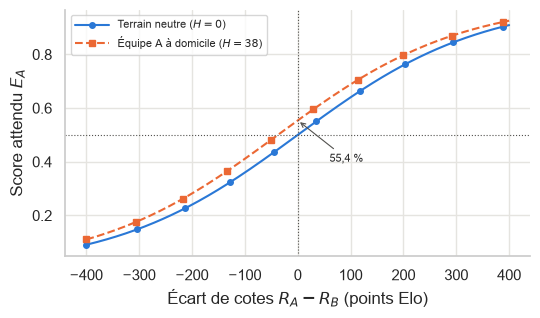

In [9]:
p_loc = matchs.loc[matchs.saison < 2008, "victoire_locale"].mean()
H_ELO = 400 * np.log10(p_loc / (1 - p_loc))
print(f"Victoires locales 2005-2008 : {p_loc:.1%} -> H = {H_ELO:.0f} points Elo")


def elo_esperance(diff, h=0.0):
    return 1 / (1 + 10 ** (-(diff + h) / 400))


dd = np.linspace(-400, 400, 400)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(dd, elo_esperance(dd), markevery=0.1, label="Terrain neutre ($H = 0$)")
ax.plot(
    dd, elo_esperance(dd, H_ELO), markevery=0.1, label=f"Équipe A à domicile ($H = {H_ELO:.0f}$)"
)
ax.axhline(0.5, color=ENCRE_2, lw=0.8, ls=":")
ax.axvline(0, color=ENCRE_2, lw=0.8, ls=":")
ax.annotate(
    f"{elo_esperance(0, H_ELO):.1%}".replace(".", ",").replace("%", " %"),
    xy=(0, elo_esperance(0, H_ELO)),
    xytext=(60, 0.4),
    fontsize=8,
    arrowprops=dict(arrowstyle="->", color=ENCRE_2, lw=0.8),
)
ax.set_xlabel("Écart de cotes $R_A - R_B$ (points Elo)")
ax.set_ylabel("Score attendu $E_A$")
ax.legend(loc="upper left", fontsize=8)
sauver(fig, "methodes_elo_esperance")
plt.show()

In [10]:
def elo_executer(df, K, h=H_ELO, retour=1 / 3):
    """Elo séquentiel sur les matchs (triés par date). Retourne les probabilités avant match et
    les cotes après chaque match (local, visiteur)."""
    R = {}
    probs = np.empty(len(df))
    apres = np.empty((len(df), 2))
    saison_prec = None
    for i, (s, dom, vis, y) in enumerate(
        df[["saison", "local", "visiteur", "victoire_locale"]].to_numpy()
    ):
        if s != saison_prec:  # retour partiel vers la moyenne entre deux saisons
            R = {e: 1500 + (1 - retour) * (r - 1500) for e, r in R.items()}
            saison_prec = s
        rd, rv = R.get(dom, 1500.0), R.get(vis, 1500.0)
        e = elo_esperance(rd - rv, h)
        probs[i] = e
        R[dom], R[vis] = rd + K * (y - e), rv - K * (y - e)
        apres[i] = R[dom], R[vis]
    return probs, apres


def trajectoire(df, apres, equipe):
    """Cote d'une équipe après chacun de ses matchs."""
    m_dom, m_vis = (df["local"] == equipe).to_numpy(), (df["visiteur"] == equipe).to_numpy()
    joue = m_dom | m_vis
    return df.loc[joue, ["date", "saison"]].assign(
        cote=np.where(m_dom, apres[:, 0], apres[:, 1])[joue]
    )

**Choix de $K$.** Un $K$ faible donne des cotes stables mais lentes à réagir à un changement
réel de force (blessures, échanges, changement de gardien) ; un $K$ élevé réagit vite mais suit
le bruit des résultats. Exemple : les Canadiens de Montréal, finalistes de la Coupe Stanley en
2021, puis derniers de la ligue en 2021-2022.

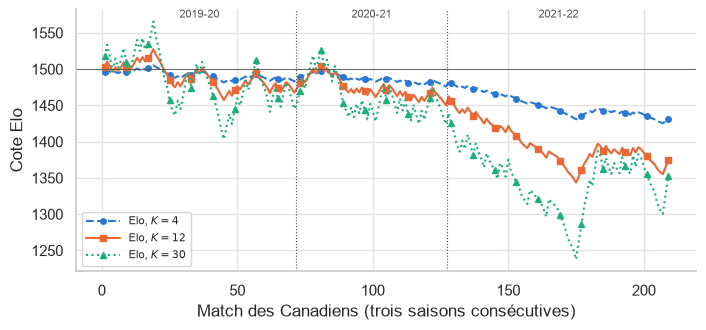

In [11]:
MTL = int(NOMS[NOMS.str.startswith("Montr")].index[0])
fig, ax = plt.subplots(figsize=(8, 3.4))
for K, c, ls, mk in [
    (4, COULEURS[0], "--", "o"),
    (12, COULEURS[1], "-", "s"),
    (30, COULEURS[2], ":", "^"),
]:
    _, apres = elo_executer(matchs, K)
    tr = trajectoire(matchs, apres, MTL)
    tr = tr[tr.saison.between(2019, 2021)].reset_index(drop=True)
    ax.plot(tr.index + 1, tr.cote, color=c, ls=ls, marker=mk, markevery=8, label=f"Elo, $K = {K}$")
for s in (2020, 2021):
    i0 = tr.index[tr.saison == s][0] + 0.5
    ax.axvline(i0, color=ENCRE_2, lw=0.8, ls=":")
for s in (2019, 2020, 2021):
    ax.text(
        tr.index[tr.saison == s].to_numpy().mean() + 1,
        ax.get_ylim()[1],
        libelle(s),
        ha="center",
        va="top",
        fontsize=8,
        color=ENCRE_2,
    )
ax.axhline(1500, color=ENCRE_2, lw=0.6)
ax.set_xlabel("Match des Canadiens (trois saisons consécutives)")
ax.set_ylabel("Cote Elo")
ax.legend(loc="lower left", fontsize=8)
sauver(fig, "methodes_elo_facteur_k")
plt.show()

Le facteur $K$ est donc un **hyperparamètre** à choisir par validation temporelle. Log loss des
probabilités Elo (calculées séquentiellement, donc toujours avant le match) selon $K$. Le
choix se fait sur les saisons d'entraînement (2008-2009 à 2021-2022) seulement : les saisons de
test ne servent qu'à l'évaluation finale, sinon le choix de $K$ « verrait » les résultats à
prédire.

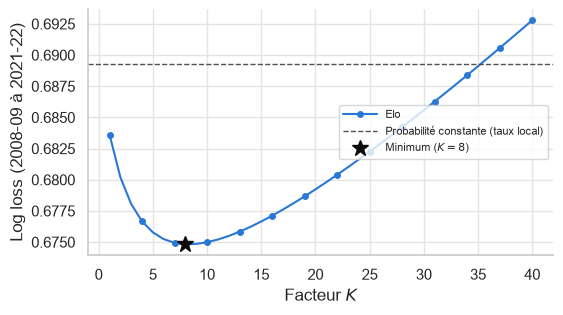

In [12]:
Ks = np.arange(1, 41)
SEL, EVAL = ENTR.to_numpy(), TEST.to_numpy()  # choix sur l'entraînement, évaluation sur le test
y_sel, y_ev = y_all[SEL], y_all[EVAL]
ll_k = np.array([log_loss(y_sel, elo_executer(matchs, K)[0][SEL]) for K in Ks])
ll_const = log_loss(y_sel, np.full(SEL.sum(), p_loc))
k_opt = int(Ks[np.argmin(ll_k)])

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(Ks, ll_k, markevery=3, label="Elo")
ax.axhline(
    ll_const, color=ENCRE_2, ls="--", marker="", lw=1, label="Probabilité constante (taux local)"
)
ax.plot(k_opt, ll_k.min(), marker="*", ms=12, color=ENCRE, ls="", label=f"Minimum ($K = {k_opt}$)")
ax.set_xlabel("Facteur $K$")
ax.set_ylabel(f"Log loss ({libelle(2008)} à {libelle(2021)})")
ax.legend(fontsize=8, loc="center right")
sauver(fig, "methodes_elo_logloss_k")
plt.show()

**Avantages.** Très peu de paramètres ($K$, $H$, retour vers la moyenne) ; mise à jour en ligne,
intrinsèquement **temporelle** (aucune fuite d'information si appliqué séquentiellement) ;
n'utilise que les résultats, donc disponible sur de longues périodes ; produit directement une
probabilité ; référence forte et difficile à battre en prédiction sportive.

**Limites.** Une seule dimension de force par équipe ; ignore les informations riches (tirs, xG,
alignement, gardien partant, repos) sauf extensions ad hoc ; aucune mesure d'incertitude sur la
cote (une équipe après 3 matchs est traitée comme après 80) ; $K$ fixe ; calibration
dépendante de l'échelle 400 et de $H$ (souvent à recalibrer).

---
## 3. Glicko et Glicko-2

**Principe.** Glicko (Glickman, 1999) ajoute à chaque cote $r$ un **écart de classement**
$RD$, qui mesure l'incertitude sur la force de l'équipe (approche bayésienne approximative,
loi normale a posteriori $\mathcal N(r, RD^2)$). Avec $q = \ln 10 / 400$ :

$$g(RD) = \frac{1}{\sqrt{1 + 3q^2 RD^2/\pi^2}}, \qquad
E = \frac{1}{1 + 10^{-g(RD_j)(r - r_j)/400}}.$$

Après un match contre $j$ :

$$d^2 = \left[q^2 g(RD_j)^2 E(1-E)\right]^{-1}, \quad
r' = r + \frac{q}{1/RD^2 + 1/d^2}\, g(RD_j)\,(s - E), \quad
RD' = \left(\frac{1}{RD^2} + \frac{1}{d^2}\right)^{-1/2}.$$

- $RD$ **diminue** à chaque match (on apprend sur l'équipe) ;
- $RD$ **augmente** pendant l'inactivité : $RD \leftarrow \min\big(\sqrt{RD^2 + c^2 t},\, 350\big)$
  ($t$ en jours ; ex. pendant l'été, après les changements d'effectif) ;
- la mise à jour est plus forte quand $RD$ est grand : c'est un **$K$ adaptatif**.

**Glicko-2** ajoute une **volatilité** $\sigma$ propre à chaque équipe (degré de fluctuation
attendu de la force). D'autres variantes existent : TrueSkill (Microsoft, inférence bayésienne
par propagation d'espérance), Elo avec écart de buts, Elo basé sur les xG.

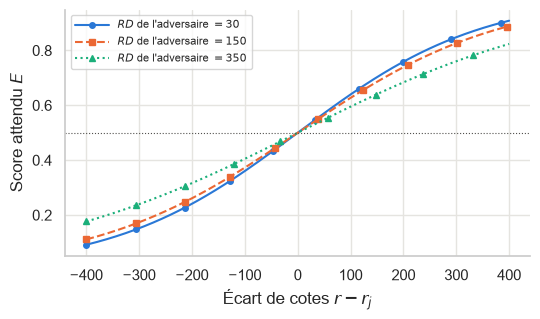

In [13]:
Q = np.log(10) / 400


def g_rd(rd):
    return 1 / np.sqrt(1 + 3 * Q**2 * rd**2 / np.pi**2)


def glicko_esperance(r, r_j, rd_j, h=0.0):
    return 1 / (1 + 10 ** (-g_rd(rd_j) * (r - r_j + h) / 400))


fig, ax = plt.subplots(figsize=(6, 3.2))
for rd in [30, 150, 350]:
    ax.plot(dd, glicko_esperance(dd, 0, rd), markevery=0.1, label=f"$RD$ de l'adversaire $= {rd}$")
ax.axhline(0.5, color=ENCRE_2, lw=0.8, ls=":")
ax.set_xlabel("Écart de cotes $r - r_j$")
ax.set_ylabel("Score attendu $E$")
ax.legend(loc="upper left", fontsize=8)
sauver(fig, "methodes_glicko_g_rd")
plt.show()

Plus l'incertitude sur l'adversaire est grande, plus la probabilité prédite est **ramenée vers
0,5** : Glicko intègre l'incertitude sur les paramètres dans la probabilité, ce qui améliore la
calibration en début de saison.

Application aux matchs de la LNH, avec le temps réel écoulé entre les matchs de chaque équipe.
Comme $K$ pour Elo, la constante d'inflation $c$ est un hyperparamètre : elle fixe le niveau
d'équilibre de $RD$, donc la vitesse d'adaptation. On la choisit sur une grille (log loss des
saisons d'entraînement, 2008-2009 à 2021-2022).

In [14]:
def glicko_executer(df, c, h=H_ELO):
    r, rd, dernier = {}, {}, {}
    probs = np.empty(len(df))
    apres = np.empty((len(df), 4))
    cols = ["date", "local", "visiteur", "victoire_locale"]
    for i, (date, dom, vis, y) in enumerate(df[cols].itertuples(index=False)):
        for e in (dom, vis):  # inflation de RD selon le temps écoulé depuis le dernier match
            t = (date - dernier[e]).days if e in dernier else 0
            rd[e] = min(np.sqrt(rd.get(e, 350.0) ** 2 + c**2 * t), 350.0)
            r.setdefault(e, 1500.0)
            dernier[e] = date
        probs[i] = glicko_esperance(r[dom], r[vis], np.hypot(rd[dom], rd[vis]), h)
        nouv = {}
        for eq, adv, s, he in [(dom, vis, y, h), (vis, dom, 1 - y, -h)]:
            gj = g_rd(rd[adv])
            e = glicko_esperance(r[eq], r[adv], rd[adv], he)
            d2 = 1 / (Q**2 * gj**2 * e * (1 - e))
            den = 1 / rd[eq] ** 2 + 1 / d2
            nouv[eq] = (r[eq] + Q / den * gj * (s - e), np.sqrt(1 / den))
        for eq, (rn, rdn) in nouv.items():
            r[eq], rd[eq] = rn, rdn
        apres[i] = r[dom], rd[dom], r[vis], rd[vis]
    return probs, apres


grille_c = {c: glicko_executer(matchs, c) for c in [1, 2, 3, 5, 10]}
ll_c = pd.Series({c: log_loss(y_sel, p[SEL]) for c, (p, _) in grille_c.items()}, name="Log loss")
ll_c.index.name = "c"
C_GLICKO = int(ll_c.idxmin())
p_glicko, apres_g = grille_c[C_GLICKO]
ll_c.round(4).to_frame().T

c,1,2,3,5,10
Log loss,0.6768,0.6757,0.6772,0.6817,0.6946


Cote des Canadiens avec l'intervalle $r \pm 1{,}96\,RD$ sur deux saisons ($c$ retenu) :
l'intervalle se resserre au fil des matchs et s'élargit pendant l'été.

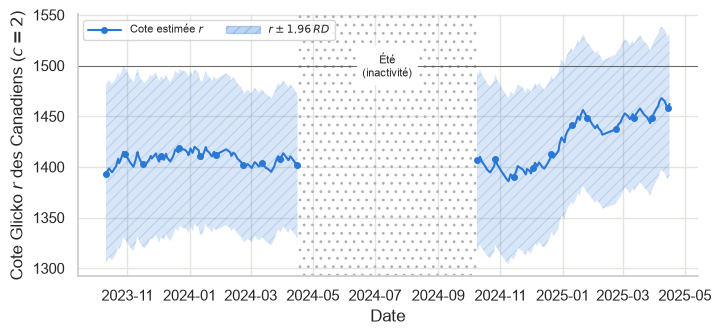

In [15]:
m_dom, m_vis = (matchs.local == MTL).to_numpy(), (matchs.visiteur == MTL).to_numpy()
tr = matchs.loc[m_dom | m_vis, ["date", "saison"]].assign(
    r=np.where(m_dom, apres_g[:, 0], apres_g[:, 2])[m_dom | m_vis],
    rd=np.where(m_dom, apres_g[:, 1], apres_g[:, 3])[m_dom | m_vis],
)
tr = tr[tr.saison.between(2023, 2024)]

fig, ax = plt.subplots(figsize=(8, 3.4))
for _, dts in tr.groupby("saison"):
    ax.fill_between(
        dts.date,
        dts.r - 1.96 * dts.rd,
        dts.r + 1.96 * dts.rd,
        facecolor=COULEURS[0],
        alpha=0.18,
        hatch="///",
        edgecolor=COULEURS[0],
        lw=0,
    )
    ax.plot(dts.date, dts.r, color=COULEURS[0], ls="-", marker="o", markevery=8)
fin_s, debut_s = tr[tr.saison == 2023].date.max(), tr[tr.saison == 2024].date.min()
ax.axvspan(fin_s, debut_s, facecolor="none", edgecolor="#b0b0b0", hatch="..", lw=0)
ax.text(
    fin_s + (debut_s - fin_s) / 2,
    1500,
    "Été\n(inactivité)",
    ha="center",
    va="center",
    fontsize=8,
    bbox=dict(fc="white", ec="none"),
)
ax.axhline(1500, color=ENCRE_2, lw=0.6)
ax.set_xlabel("Date")
ax.set_ylabel(f"Cote Glicko $r$ des Canadiens ($c = {C_GLICKO}$)")
ax.legend(
    handles=[
        plt.Line2D([], [], color=COULEURS[0], marker="o", label="Cote estimée $r$"),
        Patch(
            facecolor=COULEURS[0],
            alpha=0.3,
            hatch="///",
            edgecolor=COULEURS[0],
            label="$r \\pm 1{,}96\\,RD$",
        ),
    ],
    fontsize=8,
    loc="upper left",
    ncols=2,
)
sauver(fig, "methodes_glicko_incertitude")
plt.show()

Qualité des probabilités d'Elo et de Glicko ($K$ et $c$ choisis sur l'entraînement), calculées
séquentiellement et évaluées sur les saisons de test (2022-2023 à 2025-2026) :

In [16]:
p_elo = elo_executer(matchs, k_opt)[0]
ref = pd.DataFrame(
    [
        (
            "Probabilité constante (taux local)",
            log_loss(y_ev, np.full(EVAL.sum(), p_loc)),
            brier(y_ev, np.full(EVAL.sum(), p_loc)),
        ),
        (f"Elo (K = {k_opt})", log_loss(y_ev, p_elo[EVAL]), brier(y_ev, p_elo[EVAL])),
        (f"Glicko (c = {C_GLICKO:g})", log_loss(y_ev, p_glicko[EVAL]), brier(y_ev, p_glicko[EVAL])),
    ],
    columns=["Méthode", "Log loss", "Brier"],
).set_index("Méthode")
sauver_tableau(ref.round(4), "methodes_tab_elo_glicko")
ref.round(4)

,Log loss,Brier
Méthode,,
Probabilité constante (taux local),0.6909,0.2489
Elo (K = 8),0.6704,0.2389
Glicko (c = 2),0.6739,0.2404


**Avantages.** Conserve la simplicité et le caractère séquentiel d'Elo ; quantifie
l'incertitude sur la force de chaque équipe ; vitesse d'adaptation automatique (forte en début
de saison ou après l'été, faible ensuite) ; probabilités plus prudentes lorsque l'information
est rare.

**Limites.** Hypothèses de normalité approximatives ; paramètres supplémentaires ($c$, $\sigma$,
$\tau$ pour Glicko-2) à ajuster ; conçu au départ pour des joueurs d'échecs (périodes de
classement) ; reste un modèle à **une dimension de force** fondé uniquement sur les résultats.

---
## 4. Approches bayésiennes

**Principe.** Les paramètres $\boldsymbol\theta$ (force des équipes, coefficients) sont traités
comme des variables aléatoires. On combine une loi **a priori** $p(\boldsymbol\theta)$ avec la
vraisemblance des données $\mathcal D$ pour obtenir la loi **a posteriori** :

$$p(\boldsymbol\theta \mid \mathcal D) \propto p(\mathcal D \mid \boldsymbol\theta)\,
p(\boldsymbol\theta).$$

La prédiction intègre l'incertitude sur les paramètres (loi prédictive a posteriori) :

$$P(y^* = 1 \mid \mathbf x^*, \mathcal D) = \int \sigma(\boldsymbol\theta^\top \mathbf x^*)\,
p(\boldsymbol\theta \mid \mathcal D)\, d\boldsymbol\theta.$$

Exemples en sport : modèles de Poisson bayésiens pour les buts (Baio et Blangiardo), modèles
dynamiques à espace d'états où la force évolue dans le temps (Glickman et Stern), modèles
hiérarchiques équipes/joueurs. L'inférence se fait par conjugaison (cas simples), par MCMC
(Stan, PyMC) ou par approximations (Laplace, variationnel).

### 4.1 Mise à jour conjuguée Bêta-Binomiale

Probabilité de victoire $p$ d'une équipe, a priori $\text{Bêta}(\alpha, \beta)$. Après $w$
victoires en $n$ matchs, l'a posteriori est $\text{Bêta}(\alpha + w,\ \beta + n - w)$ : l'a
priori agit comme $\alpha + \beta$ matchs fictifs. L'a priori est estimé (méthode des moments)
sur la dispersion des pourcentages de victoires des équipes-saisons de 2005-2006 à 2024-2025,
corrigée du bruit binomial.

A priori : Bêta(18.8, 18.8) — moyenne 0.500, écart-type des vraies forces 0.081, équivalent à 38 matchs fictifs


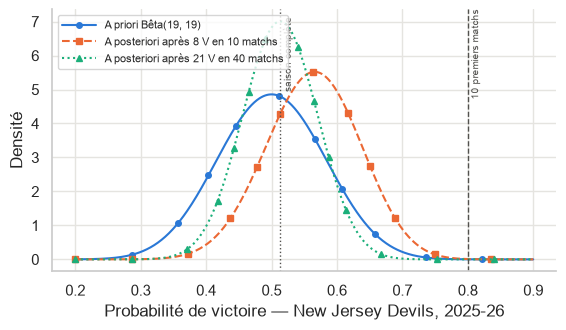

In [17]:
eqs = equipes.sort_values(["date", "gameId"])
eqs = eqs.assign(
    victoire=eqs["wins"].astype(int), rang=eqs.groupby(["saison", "teamId"]).cumcount() + 1
)
hist = eqs[eqs.saison < 2025].groupby(["saison", "teamId"])["victoire"].agg(["mean", "size"])
m_h, n_h = hist["mean"].mean(), hist["size"].mean()
var_vraie = hist["mean"].var() - m_h * (1 - m_h) / n_h
s_ab = m_h * (1 - m_h) / var_vraie - 1
A0, B0 = m_h * s_ab, (1 - m_h) * s_ab
print(
    f"A priori : Bêta({A0:.1f}, {B0:.1f}) — moyenne {m_h:.3f}, écart-type des vraies forces "
    f"{np.sqrt(var_vraie):.3f}, équivalent à {s_ab:.0f} matchs fictifs"
)

s25 = eqs[eqs.saison == 2025]
debut = s25[s25.rang <= 10].groupby("teamId")["victoire"].sum()
EQ = int(debut.idxmax())
v = s25[s25.teamId == EQ].set_index("rang")["victoire"]
w10, w40, final = int(v.loc[:10].sum()), int(v.loc[:40].sum()), v.mean()

p = np.linspace(0.2, 0.9, 500)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for nom, a, b in [
    (f"A priori Bêta({A0:.0f}, {B0:.0f})", A0, B0),
    (f"A posteriori après {w10} V en 10 matchs", A0 + w10, B0 + 10 - w10),
    (f"A posteriori après {w40} V en 40 matchs", A0 + w40, B0 + 40 - w40),
]:
    ax.plot(p, stats.beta.pdf(p, a, b), markevery=0.1, label=nom)
for val, lab, ls in [(w10 / 10, "10 premiers matchs", "--"), (final, "saison complète", ":")]:
    ax.axvline(val, color=ENCRE_2, lw=1, ls=ls)
    ax.text(
        val + 0.005,
        ax.get_ylim()[1] * 0.82,
        lab,
        fontsize=7,
        color=ENCRE_2,
        rotation=90,
        va="center",
    )
ax.set_xlabel(f"Probabilité de victoire — {NOMS[EQ]}, {libelle(2025)}")
ax.set_ylabel("Densité")
ax.legend(fontsize=8, loc="upper left")
sauver(fig, "methodes_bayes_beta")
plt.show()

Après un début de saison exceptionnel, l'estimation a posteriori reste beaucoup plus près de la
moyenne que la proportion observée : l'a priori **régularise** les estimations fondées sur peu
de matchs. À mesure que les matchs s'accumulent, les données dominent et la loi se resserre.

### 4.2 Régression logistique bayésienne

Même modèle que la régression logistique (variable : écart de xG%, standardisée), avec a priori
$\beta_j \sim \mathcal N(0, 2{,}5^2)$. La loi a posteriori est échantillonnée par
**Metropolis** (MCMC). La bande de crédibilité à 90 % de $P(y = 1 \mid x)$ est beaucoup plus
large avec 30 matchs qu'avec 300 : le modèle sait ce qu'il ne sait pas. La courbe noire est la
régression logistique ajustée sur tous les matchs d'entraînement (référence).

n = 30 : acceptation 61%, beta_1 a posteriori = 1.59 ± 0.71 (par écart-type de x)
n = 300 : acceptation 48%, beta_1 a posteriori = 0.17 ± 0.11 (par écart-type de x)


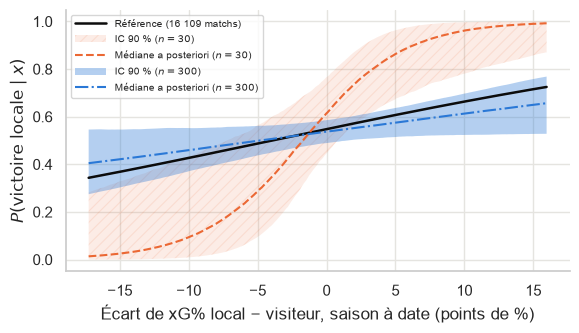

In [18]:
def log_post(th, x, y, sd_prior=2.5):
    eta = th[0] + th[1] * x
    return np.sum(y * eta - np.logaddexp(0, eta)) - 0.5 * np.sum(th**2) / sd_prior**2


def metropolis(x, y, n_iter=30_000, burn=5_000, seed=0):
    r = np.random.default_rng(seed)
    pas = 2.4 / np.sqrt(len(x))
    th, lp = np.zeros(2), log_post(np.zeros(2), x, y)
    ech, acc = np.empty((n_iter, 2)), 0
    for i in range(n_iter):
        prop = th + pas * r.normal(size=2)
        lpp = log_post(prop, x, y)
        if np.log(r.random()) < lpp - lp:
            th, lp, acc = prop, lpp, acc + 1
        ech[i] = th
    return ech[burn:], acc / n_iter


mu, sd = x1.mean(), x1.std()
xs_all, ys_all = (x1 - mu) / sd, d["victoire_locale"].to_numpy()
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(
    xg,
    expit(b0 + b1 * xg),
    color=ENCRE,
    ls="-",
    marker="",
    lw=1.8,
    label=f"Référence ({len(x1):,} matchs)".replace(",", " "),
)
for n_obs, c, ls, hachure, alpha in [
    (30, COULEURS[1], "--", "///", 0.12),
    (300, COULEURS[0], "-.", "", 0.35),
]:
    idx = rng.choice(len(xs_all), n_obs, replace=False)
    ech, taux = metropolis(xs_all[idx], ys_all[idx], seed=n_obs)
    pp = expit(ech[::10, [0]] + ech[::10, [1]] * ((xg - mu) / sd))
    bas, med, haut = np.quantile(pp, [0.05, 0.5, 0.95], axis=0)
    ax.fill_between(
        xg,
        bas,
        haut,
        facecolor=c,
        alpha=alpha,
        hatch=hachure,
        edgecolor=c,
        lw=0,
        label=f"IC 90 % ($n = {n_obs}$)",
    )
    ax.plot(xg, med, color=c, ls=ls, marker="", label=f"Médiane a posteriori ($n = {n_obs}$)")
    print(
        f"n = {n_obs} : acceptation {taux:.0%}, beta_1 a posteriori = "
        f"{ech[:, 1].mean():.2f} ± {ech[:, 1].std():.2f} (par écart-type de x)"
    )
ax.set_xlabel("Écart de xG% local − visiteur, saison à date (points de %)")
ax.set_ylabel("$P(\\text{victoire locale} \\mid x)$")
ax.legend(fontsize=7.5, loc="upper left")
sauver(fig, "methodes_bayes_logistique_predictive")
plt.show()

### 4.3 Modèle hiérarchique et rétrécissement (*shrinkage*)

Dans un modèle **hiérarchique**, les forces des équipes partagent une loi commune dont les
paramètres sont eux-mêmes estimés : l'information est mise en commun entre équipes
(*partial pooling*). Ici, approche **bayésienne empirique** : la loi Bêta commune est celle
estimée en 4.1 sur les équipes-saisons passées, puis chaque équipe de 2025-2026 est mise à jour
après ses 10 premiers matchs. On compare ensuite chaque estimation au pourcentage de victoires
sur le **reste de la saison** (matchs 11 à 82).

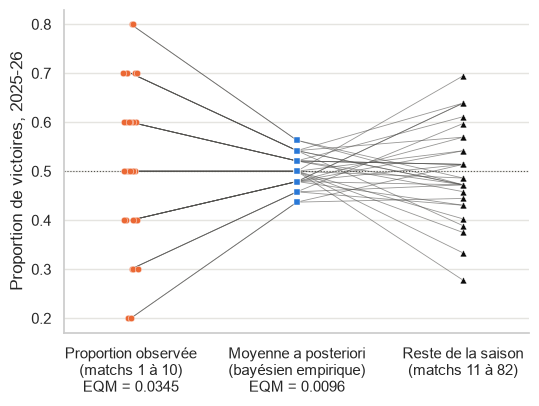

A priori : Bêta(18.8, 18.8) ; erreur quadratique réduite de 72%


In [19]:
n_m = 10
w_eq = s25[s25.rang <= n_m].groupby("teamId")["victoire"].sum()
reste = s25[s25.rang > n_m].groupby("teamId")["victoire"].mean().reindex(w_eq.index)
brut = w_eq / n_m
moy = A0 / (A0 + B0)
post = (w_eq + A0) / (n_m + A0 + B0)
eqm_brut, eqm_post = np.mean((brut - reste) ** 2), np.mean((post - reste) ** 2)

fig, ax = plt.subplots(figsize=(6, 4.2))
pos = [0, 1, 2]
gigue = rng.uniform(-0.05, 0.05, len(brut))
for i in range(len(brut)):
    ax.plot(
        pos,
        [brut.iloc[i], post.iloc[i], reste.iloc[i]],
        color=ENCRE_2,
        lw=0.6,
        alpha=0.6,
        marker="",
        ls="-",
    )
ax.scatter(gigue, brut, marker="o", s=22, color=COULEURS[1], edgecolor="white", lw=0.3, zorder=3)
ax.scatter(
    np.ones(len(post)),
    post,
    marker="s",
    s=22,
    color=COULEURS[0],
    edgecolor="white",
    lw=0.3,
    zorder=3,
)
ax.scatter(
    np.full(len(reste), 2),
    reste,
    marker="^",
    s=24,
    color=ENCRE,
    edgecolor="white",
    lw=0.3,
    zorder=3,
)
ax.axhline(moy, color=ENCRE_2, ls=":", lw=0.8)
ax.set_xticks(
    pos,
    [
        f"Proportion observée\n(matchs 1 à {n_m})\nEQM = {eqm_brut:.4f}",
        f"Moyenne a posteriori\n(bayésien empirique)\nEQM = {eqm_post:.4f}",
        f"Reste de la saison\n(matchs {n_m + 1} à 82)",
    ],
)
ax.set_xlim(-0.4, 2.4)
ax.set_ylabel(f"Proportion de victoires, {libelle(2025)}")
ax.grid(axis="x", visible=False)
sauver(fig, "methodes_bayes_retrecissement")
plt.show()
print(
    f"A priori : Bêta({A0:.1f}, {B0:.1f}) ; "
    f"erreur quadratique réduite de {1 - eqm_post / eqm_brut:.0%}"
)

**Avantages.** Quantification explicite de l'incertitude (intervalles de crédibilité, loi
prédictive) ; intégration de connaissances a priori (parité de la ligue, saison précédente) ;
régularisation naturelle par le rétrécissement, utile en début de saison ou pour les joueurs
ayant peu de matchs ; structures hiérarchiques (joueurs → équipes) et dynamiques (force variant
dans le temps) exprimées directement dans le modèle.

**Limites.** Coût de calcul (MCMC) élevé pour de grands modèles ou des mises à jour
fréquentes ; choix et justification des lois a priori ; diagnostic de convergence nécessaire ;
relations le plus souvent paramétriques (linéaires sur le logit), donc moins flexibles que les
méthodes d'ensemble d'arbres sans travail de modélisation.

---
## 5. Tableau synthèse

In [20]:
synthese = pd.DataFrame(
    [
        (
            "Régression logistique",
            "Logit linéaire en x, maximum de vraisemblance (± pénalité L1/L2)",
            "Vecteur de variables (écarts locale − visiteuse)",
            "Interprétable, peu de données, minimise la log loss, bonne calibration",
            "Linéaire, interactions manuelles, sensible à la colinéarité, pas de dynamique",
        ),
        (
            "Elo (et variantes)",
            "Cote par équipe, mise à jour K·(S − E) après chaque match",
            "Résultats des matchs (± écart de buts)",
            "Séquentiel, peu de paramètres, référence forte, sans fuite",
            "Une seule dimension de force, pas d'incertitude, K fixe, info limitée",
        ),
        (
            "Glicko / Glicko-2",
            "Elo + écart de classement RD (+ volatilité σ)",
            "Résultats des matchs, temps entre les matchs",
            "Incertitude sur la force, K adaptatif, prudence en début de saison",
            "Approximations normales, plus de paramètres, une dimension de force",
        ),
        (
            "Approches bayésiennes",
            "A priori × vraisemblance → a posteriori ; prédiction intégrée",
            "Variables et/ou résultats, structure hiérarchique ou dynamique",
            "Incertitude explicite, a priori, rétrécissement, modèles hiérarchiques",
            "Coût de calcul (MCMC), choix des a priori, souvent paramétriques",
        ),
    ],
    columns=["Méthode", "Principe", "Données d'entrée", "Avantages", "Limites"],
).set_index("Méthode")
sauver_tableau(synthese, "methodes_tab_statistiques")
synthese

,Principe,Données d'entrée,Avantages,Limites
Méthode,,,,
Régression logistique,"Logit linéaire en x, maximum de vraisemblance (± pénalité L1/L2)",Vecteur de variables (écarts locale − visiteuse),"Interprétable, peu de données, minimise la log loss, bonne calibration","Linéaire, interactions manuelles, sensible à la colinéarité, pas de dynamique"
Elo (et variantes),"Cote par équipe, mise à jour K·(S − E) après chaque match",Résultats des matchs (± écart de buts),"Séquentiel, peu de paramètres, référence forte, sans fuite","Une seule dimension de force, pas d'incertitude, K fixe, info limitée"
Glicko / Glicko-2,Elo + écart de classement RD (+ volatilité σ),"Résultats des matchs, temps entre les matchs","Incertitude sur la force, K adaptatif, prudence en début de saison","Approximations normales, plus de paramètres, une dimension de force"
Approches bayésiennes,A priori × vraisemblance → a posteriori ; prédiction intégrée,"Variables et/ou résultats, structure hiérarchique ou dynamique","Incertitude explicite, a priori, rétrécissement, modèles hiérarchiques","Coût de calcul (MCMC), choix des a priori, souvent paramétriques"
